In [1]:
#the main notebook starts here
from ngsolve import *
import numpy as np
from ngsolve.webgui import Draw
ngsglobals.msg_level = 1
import ipywidgets as widgets
import matplotlib.pyplot as plt
import h5py
#import sksparse.cholmod
#from sksparse.cholmod import cholesky
#from scipy.sparse import csc_matrix
#from scipy.linalg import cholesky

from pathlib import Path
import pandas as pd
from torchvision.datasets.utils import download_url
from tqdm import tqdm

from domain import *
from implicit import implicit
from implicit_update import implicit_update
from download import parse_metadata, download_data, download_darcy
from functions import *

In [2]:
# import darcy file - has to be in directory
try:
    with h5py.File('2D_DarcyFlow_beta100.0_Train.hdf5', 'r') as f:
        #print(list(f.keys()))
        nu = f['/nu'][:]
        tensor = f['/tensor'][:] # tensor with data as nested list of 10000x1x128x128
except:
    print("Check if the name of the file is correct. If the file is already downloaded, check if it is in the correct directory, sometimes the downloading creates a subdirectory")
    download_darcy()

#choose which sample to use - maybe build a loop with multiple samples later
sample = 21
#print(nu[sample])
#print(tensor[sample])

#general parameters
#CHANGE
sigma = 0 #switching parameter (0 e.g. if f is linear wrt q) 
L = 5 #parameter if the functional in the u update is implemented as a simple multiplication

tstart = 0
tend = 1.5
tsteps = int(1e3)

t = Parameter(tstart) #time parameter that will be updated
dt = (tend-tstart)/tsteps

k_u, k_q = 3, 0 # order of feses
maxh = 0.08 # mesh size for domain

# Build domain
dom = domain(maxh = maxh, order_u = k_u, order_q = k_q)
# Build mesh and FE spaces (Ufes for the u update and Qfes for the q update)
mesh, Ufes, Qfes = dom.mesh, dom.Ufes, dom.Qfes

np_random = [np.random.rand(128,128) for _ in range(tsteps+1)]

In [3]:
class grad_bilinear_ufes:
    def __init__(self, q = 0, M = 1):
        if q:
            self.qn = norm(q)
        else:
            self.qn = 0
        self.M = M
        self.fes = Ufes

        # For the case where there is actual q dependence, it would be much better to let this be a parameter and update accordingly
        self.bilinearform = BilinearForm(self.fes)
        self.bilinearform += self.M * Grad(self.fes.TrialFunction()) * Grad(self.fes.TestFunction()) * dx
        self.bilinearform.Assemble()

    def apply(self, f):#where is this used
        #return -self.M * (f.Diff(x).Diff(x) + f.Diff(y).Diff(y))# doesn work for grid function
        return -self.M * (grad(grad(f)[0])[0]+grad(grad(f)[1])[1])
class grad_bilinear_qfes:
    def __init__(self):
        self.fes = Qfes
        self.space = Qfes
        # For the case where there is actual q dependence, it would be much better to let this be a parameter and update accordingly
        self.bilinearform = BilinearForm(self.fes)
        self.bilinearform += Grad(z) * self.fes.TrialFunction() * Grad(self.fes.TestFunction()) * dx
        self.bilinearform.Assemble()

In [5]:
chosen_sample = tensor[sample][0]
u_exact = GridFunction(Ufes)
#u_exact.Set(to_gridfunc(chosen_sample, Ufes, mesh))
#u_exact.Set(sin(pi*x)*sin(pi*y)*exp(-t))#to_gridfunc(sin(x)*sin(y), Ufes, mesh)#to_gridfunc(chosen_sample, Ufes, mesh)
#u_exact_dt = u_exact.Diff(t) #parameter dependent

if sample == 21: #move the 1-zone to the middle for the 0th sample
    param = list(nu[sample])
    param = param[:30]+param[30:]
else: param = list(nu[sample])
# bring q_exact to 0 at the bnd in the process of setting q_exact


q_exact = CF(0)#to_gridfunc_0(param, Qfes, mesh)
Draw(q_exact,mesh)

#Set up Gridfunctions, that will updated trough the time steps
gfu, gfq, z, z_old = GridFunction(Ufes), GridFunction(Qfes), GridFunction(Ufes), GridFunction(Ufes)

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.23…

In [6]:
# compute some u_exact from a paramter q and rhs # version with implicit solver - note that the implicit solver is not yet optimized for non hom. Dirichlet BC
dom2 = domain(maxh = 0.07, order_u = 3, order_q = k_q)
mesh2, V = dom2.mesh, dom2.Ufes
u,v = V.TestFunction(),V.TrialFunction()
gf = GridFunction (V)
# set up the bilinear form according to the equation
a = BilinearForm (V, symmetric=True)
a += Grad(u) * Grad(v) * dx
a += - q_exact * q_exact * u * v * dx
#a += -gf * u * v *dx

#Define the linearform (RHS)
coef_f = 2*exp(-((x-0.5)*(x-0.5)/.05+(y-0.45)*(y-0.5)/.1))*exp(-t) # gaussian
coef_0  = GridFunction(V)
coef_0.Set(coef_f)
f = LinearForm(V)
f += coef_f * dx

t.Set(0)
gf.Set((2*exp(-((x-0.5)*(x-0.5)/.05+(y-0.45)*(y-0.5)/.1))))
#gf.Set(0)
u_exact = [None for i in range (tsteps)]
u_exact_dt = [None for i in range (tsteps)]
counter = 0


while counter<tsteps-dt:
    a.Assemble() #assemble here to get most up to date gf
    f.Assemble()
    implicit_gen = implicit(bilinearform = a, fes = V, dt = dt) # set solver only at this point as we assemble a before
    implicit_gen.solve_implicit(gf, coef_f, CF(0),gf)
    auxil = GridFunction(Ufes) 
    auxil.Set (gf)
    u_exact[counter] = GridFunction(Ufes) 
    #u_exact[counter].vec.data = a.mat.Inverse(freedofs = V.FreeDofs())*f.vec
    u_exact[counter].vec.data = auxil.vec.data
    #if counter>0: u_exact_dt[counter] = (u_exact[counter]-u_exact[counter-1])/dt #has to be computed as a differential quotient
    #else: u_exact_dt[counter] = (u_exact[counter])/dt #insert u_exact if nessasary
    counter += 1
    t.Set(t.Get()+dt)
Draw(u_exact[0])
Draw(u_exact[99])

#print(norm(exact-u_exact[179])/norm(u_exact[179]))

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.23…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.23…

BaseWebGuiScene

0.0/

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.23…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.23…

0.0015/

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.23…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.23…

... (9 outputs left out)

0.0075/

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.23…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.23…

1.4970000000000012/noiselevel: 0.0


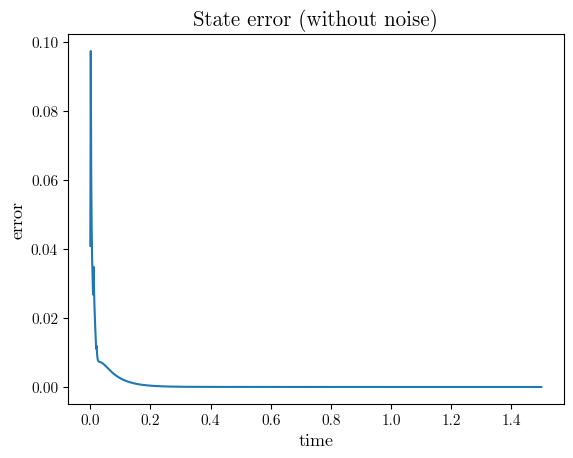

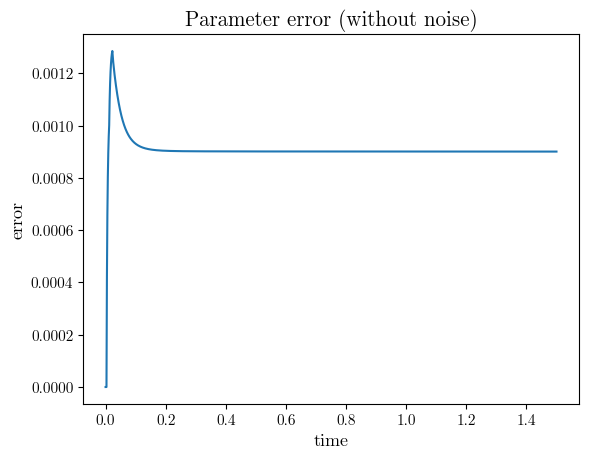

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

0.0/

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.23…

... (13 outputs left out)

0.0075/

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.23…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {}, 'ngsolve_version': '6.2.23…

1.4970000000000012/noiselevel: 0.05


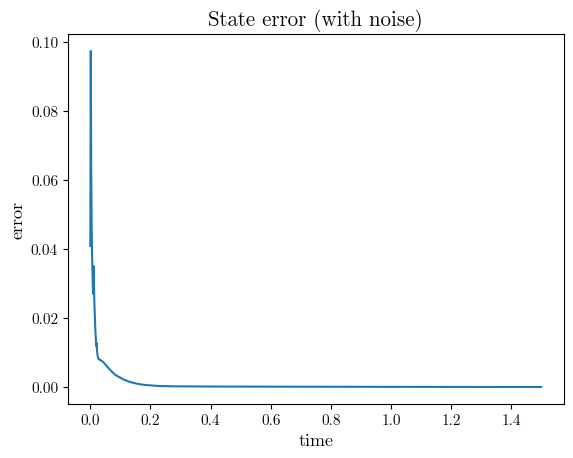

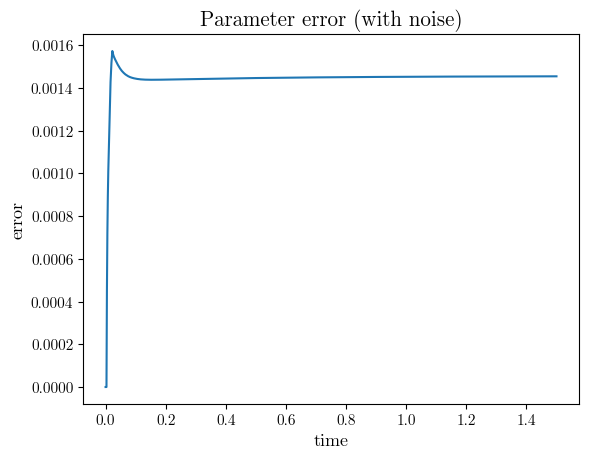

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

In [7]:
# set up a joint space to allow for a joint update
X = FESpace([Ufes,Qfes])
u, q = X.TrialFunction()
v, s = X.TestFunction()
gf = GridFunction(X)
# MRAS
for noise_level in [0.0,0.05]:  #different noise levels
    saved_gfu = []
    saved_gfq = []
    # Initial u and q
    gfu.Set(coef_0)
    r = (x-.5)**2 + (y-.5)**2
    radius = .45
    gfq.Set(0)#IfPos(radius**2 - r,1,0))
    #initial error computation
    error_u = [norm(gfu-u_exact[0],mesh)]
    error_q = [norm(gfq-q_exact,mesh)]
    t.Set(0)
    z_old.Set(CF(0))
    while t < tend-dt:
        print("\r",t.Get(),"/",sep="",end="")
        # Get updated data z and g and compute time derivative zt
        z =  add_noise(u_exact[int(t.Get()/dt)],noise_level,Ufes,mesh)
        zt = GridFunction(Ufes)
        zt.vec.data = z.vec.Copy()
        zt.vec.data -= z_old.vec.Copy()#u_exact_dt[int(t.Get()/dt)]#
        zt.vec.data /= dt
        #g = u_exact_dt[int(t.Get()/dt)] + f(q_exact, u_exact[int(t.Get()/dt)])
        g = GridFunction(Ufes)
        g.Set(coef_f)#.vec.data = coef_f.vec.Copy() # gaussian
        
        #joint solve
        a = BilinearForm(X)
        a += u * v * dx 
        a += dt * L * Grad(u) * Grad(v) * dx # from C(\|q\|) #change?
        a += -dt * gfq * q * z * v * dx # f(q,z_old) #change #check sign
        
        a += q * s * dx
        a += -dt * sigma * gfq * q * z * s * dx #f(q,z_old) in the sigma term  done implicitly
        a.Assemble()
        ########## CHANGE DOMAIN to stokes domain and look into u_exact and q_exact
        res = LinearForm(X)
        res += gfu * v * dx
        res += dt * g * v * dx #f(q,z_old)# changed
        res += dt *(-1)*Grad(z_old) * Grad(v) * dx # f(q,z_old) #changed
        res += dt * L * Grad(z_old) * Grad(v) * dx # from C(\|q\|) #change
        
        res += gfq * s * dx
        res += dt * (-2) * z_old * (gfu-z_old) * s * dx # f'_q(q,z) #check if gfu and z are consistent
        res += -dt * sigma * (zt-g) * s * dx # f(q,z_old) in the sigma term
        res += -dt * sigma * Grad(z_old) * Grad(s) * dx #f(q,z_old) in the sigma term  done implicitly 

        res.Assemble()
        try:
            inv = a.mat.Inverse(freedofs=X.FreeDofs(), inverse="umfpack")
        except Exception as e:
            print("error while inverting:", e)
            break
        gf.vec.data = inv * res.vec
        
        gfu.Set(gf.components[0])
        error_q.append(norm(gfq-q_exact,mesh))
        saved_gfq.append(gfq.vec.FV().NumPy().copy())
        gfq.Set(gf.components[1])         
        error_u.append(norm(gfu-u_exact[int(t.Get()/dt)],mesh))
        saved_gfu.append(gfu.vec.FV().NumPy().copy())
        t += dt    # Update time
        z_old.vec.data = z.vec.Copy()
        if t<0.01:
            Draw(gfu)
            Draw(gfq)
    print("noiselevel: "+str(noise_level))
    plot_error(tstart,tend,tsteps,noise_level,error_u,error_q)
    draw_gridfuncs (tsteps,u_exact,q_exact,gfu,gfq,mesh)
    save (mesh,noise_level,saved_gfu,saved_gfq)   

In [8]:
Draw(u_exact[tsteps-1]-gfu,mesh, settings={"Objects": {"Wireframe": False}})
Draw(q_exact-gfq,mesh, settings={"Objects": {"Wireframe": False}})

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

WebGuiWidget(layout=Layout(height='50vh', width='100%'), value={'gui_settings': {'Objects': {'Wireframe': Fals…

BaseWebGuiScene